# 02 | Results and the research briefing

**10 minutes | Core question: Which gains are supported, and which can be attributed to WorldGym?**

Read the narrative and saved outputs directly. Code cells provide optional CPU checks. Evidence snapshot: October 15, 2026.

![Separate rounds: selection 94/100 versus a strong selector at 93/100; native RL 13/100 versus SFT 19/100; additional SFT 53/100 versus ACT40 91/100; static predictions improve while moving predictions worsen.](media/figures/02_results.png)

[Open the full-size teaching image](media/figures/02_results.png). AI-generated schematic; actual experiment images and numerical evidence appear below.

**How to read the image:** Read each card as its own question: what changed, what was the control, and what can explain the difference? The rounds use different test scenes. In R3, additional SFT means more training on the same demonstrations.

> **Remember:** The defensible contribution is a compact implementation, matched comparisons and failure diagnosis. SFT gains are not WorldGym RL gains.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'briefing_utils.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
get_ipython().run_line_magic('matplotlib', 'inline')
from briefing_utils import *
assert verify_assets() > 0

## Main finding

The project delivers a reproducible system, actual training and controlled diagnostics. **The clearest policy gains come from additional SFT; a unique WorldGym policy benefit has not been established.** A local repair improves static predictions while worsening moving-action predictions.

Each panel below is a separate experiment. Within a round, methods share the same 100 test scenes. Across rounds, test scenes and policy families differ. **The three panels are not one learning curve.**

WG means WorldGym, LR means learning rate, mixed retains the original mixed-precision training, and FP32 uses 32-bit master weights. The numbers in FT40, ACT40 and ACT80 refer to demonstration counts, not successes.

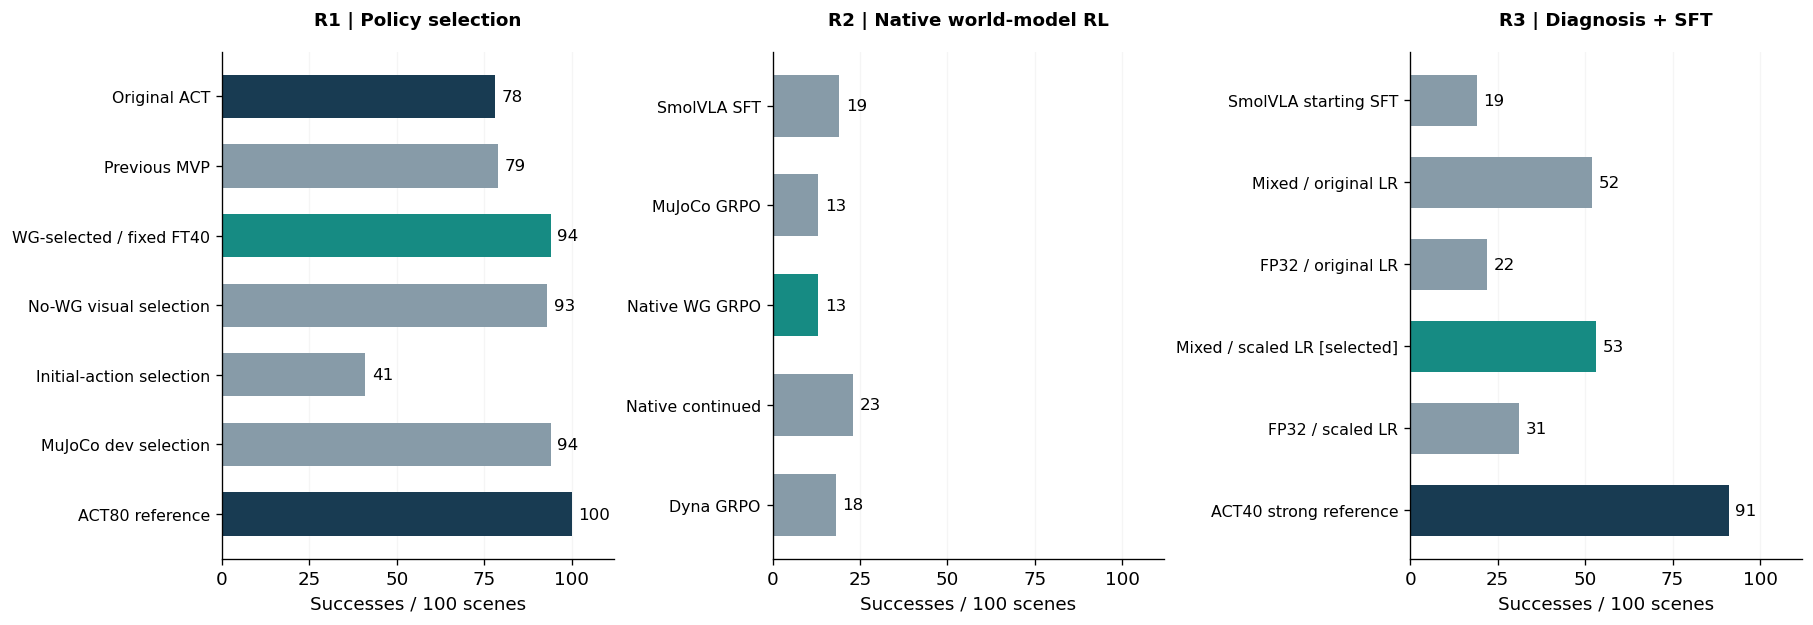

In [2]:
result_panels()

## One finding per round

**R1: a better policy was selected, but attribution is limited.** The WorldGym-selected policy achieves 94/100 versus the original ACT's 78/100. A strong no-WorldGym visual selector already achieves 93/100, and fixed FT40 itself achieves 94/100. This supports the utility of more data and an SFT candidate bank; it does not isolate a unique WorldGym selection or RL contribution. ACT80 reaches 100/100 with more demonstrations and is not a matched data-budget comparison.

**R2: native model-based RL was actually run.** SFT achieves 19/100, native WorldGym GRPO 13/100, and matched MuJoCo GRPO 13/100. Dyna achieves 18/100 versus 23/100 for matched continuation with the fixed world model. Initial-observation TTT goes from 0/4 to 0/4 on four exploratory scenes; this small zero difference does not establish equivalence.

**R3: additional SFT improves the starting point, but the strong reference remains better.** The SmolVLA candidate selected on development scenes improves from 19/100 to 53/100 on new confirmation scenes; ACT40 scores 91/100 on the same scenes. Original-LR mixed SFT already scores 52/100, so the gain cannot all be credited to LR scaling. More complete FP32 numerical updates do not translate into better physical success.

## Paired comparisons include both gains and new failures

A change of +34 pp means 34 percentage points. A gained scene is one where the new policy succeeds and the reference fails; a new failure is the reverse. Successes and paired differences below are recomputed from saved CSV outcomes. Intervals are read from the original experiment reports.

In [3]:
paired_rows = comparison_table()

Round,Paired comparison,Change (pp),Archived 95% interval,Gained scenes,New failures
R1,WG-selected - original ACT,+16,"[7, 25]",20,4
R1,WG-selected - no-WG visual selector,+1,"[-5, 8]",6,5
R2,Native WG RL - SFT,-6,"[-14, 2]",6,12
R2,Dyna RL - matched continuation,-5,"[-15, 5]",11,16
R3,Selected SFT - starting SFT,+34,"[21, 47]",44,10
R3,Selected SFT - ACT40,-38,"[-48, -28]",2,40
R3,Scaled LR - original LR (mixed),+1,"[-6, 8]",7,6


The 95% intervals use **scene-paired resampling**. They describe uncertainty across the sampled initial conditions, not variation across independently trained models. R2 and R3 use one policy-training seed and one pickup task.

## What might be limiting model-based RL?

The world-model repair compares two updates from the same starting weights and with the same optimization budget: replay-only data versus a mixture containing stationary-action data. All 36 predictions are retained: four new initial states, three actions and three models. MAE is mean absolute pixel error between predicted and matching physics-simulation views; lower is better.

In [4]:
diagnostic_tables()

Matched initial state and action,Replay-only MAE,Hold-mix MAE,Relative error change (lower is better)
Hold still,0.0491,0.0327,-33.5%
Move,0.0751,0.0802,+6.8%
Reverse gripper,0.0867,0.0881,+1.6%


VLM reward (192 frames),Balanced accuracy (higher is better),False positives,False negatives
Original reward,91.6%,18,0
Prompt only,87.5%,13,11
Prompt + weight update,81.3%,6,27


**World model.** Hold-mix reduces mean static error by about 33% relative to replay-only, with improvement in 3/4 initial states. Moving-action prediction is worse in 4/4 states; reverse-gripper prediction improves in two and worsens in two. Pure VAE encode/decode error is about 0.0059, much smaller than the base model's static prediction error of 0.0594, so compression alone does not explain the drift. A separate action-effect error decreases on average for both interventions but retains individual regressions. These are small prediction diagnostics, not evidence of policy improvement.

**VLM reward.** On 12 new scenes, two policies and eight sampled frames per trajectory, the repair reduces false positives but increases false negatives, lowering balanced accuracy. Balanced accuracy averages the recognition rates for successful and unsuccessful frames. The 192 frames are correlated within trajectories; they are not 192 independent scenes. A separate generated/physical alignment diagnostic has only one physical positive, whose generated counterpart both rewards miss. This is insufficient evidence that reward is reliable in the model-generated domain.

**Engineering fixes and limits.** RL checkpoint reload precision was repaired and likelihood/optimizer steps were checked. Empty instructions and empty images receive explicit rejection rules. These are input contracts, not general out-of-distribution detection. Both ACT and SmolVLA execute cached 50-step action chunks; an alleged ACT-10 versus SmolVLA-50 interface bug was not confirmed.

## A 90-second research briefing

> I built a reproducible local testbed around a single simulated test-tube pickup task. It covers supervised fine-tuning, policy evaluation, and native WorldGym rollouts scored by a task-adapted VLM, with actual GRPO updates to a compact SmolVLA policy. I also ran small Dyna and initial-observation adaptation experiments.
>
> The clearest policy gains came from supervised learning. In the selection study, the WorldGym-selected policy achieved 94 out of 100, while a strong selection baseline without WorldGym achieved 93. In the native RL study, SFT achieved 19 out of 100 and WorldGym RL achieved 13. In a separate fresh confirmation, additional SFT improved the starting policy from 19 to 53, but ACT40 reached 91.
>
> The diagnostics exposed a useful tradeoff: reducing static world-model drift worsened moving-action prediction, and reducing VLM false positives increased false negatives. My proposed next step is to improve action and contact fidelity, then isolate its downstream RL effect under matched policy, reward and training budgets. These are single-task simulation results, not a real-robot or full-scale paper reproduction.

## Contribution claims supported by the evidence

| Work | Evidence boundary |
|---|---|
| Compact native WorldGym RL loop on one 16GB GPU | Executed policy updates, saved trajectories, numerical checks and new-scene evaluation |
| Separating SFT, selector and model-based RL contributions | Strong references and paired gains/regressions reported; unique WorldGym benefit not established |
| Static drift, action response and VLM error diagnosis | Small matched studies guide the next experiment; they do not establish generality |
| State-of-the-art success, real-robot readiness or full-scale reproduction | Not supported by the current results |

Next: [The next WorldGym RL experiment](03_next_worldgym_rl.ipynb).

<details><summary>Saved examples, actual cost and original evidence</summary>

The first gain and first new failure in the frozen scene order compare the starting SFT with selected SFT. They are **not RL success examples**: [gain video](media/demos/policy_improvement.mp4), [new-failure video](media/demos/policy_regression.mp4).

Native-model comparisons use one fixed new initial state: [hold still](media/demos/world_model_static.mp4), [move](media/demos/world_model_motion.mp4).

Actual round wall times were approximately 6h39m, 8h04m and 5h18m. These include each round's preparation, computation and delivery, not just active GPU time. See [R1](SOURCE_MANIFEST.json), [R2](SOURCE_MANIFEST.json), [R3](SOURCE_MANIFEST.json).

Numerical sources: [R1 CSV](evidence/gain_outcomes.csv), [R2 CSV](evidence/native_outcomes.csv), [R3 CSV](evidence/repair_outcomes.csv), [R3 paired intervals](evidence/repair_results.json), [diagnostics](evidence/repair_diagnostics.json), [per-state WM comparisons](evidence/wm_paired_summary.json). These opened historical final sets cannot be called unseen confirmation data for a future experiment.

</details>